|<img src="https://www.udp.cl/cms/wp-content/uploads/2021/06/UDP_LogoRGB_2lineas_Color_SinFondo.png" width="450" height="90">| <p><b>Ciencia de Datos para la Economía</b></p><p><b>Escuela de Ingeniería Comercial - Universidad Diego Portales</b></p><p><b>Profesor:</b> Luis Cuevas Parra</p><p><b>Modelos de Machine Learning:</b> Regularización con Ridge, Lasso y Elastic Net</p>|
|---|---|

# Regularización en Modelos de Pronóstico: Ridge, Lasso y Elastic Net

> **Objetivo de la sesión:**
> Aprender a construir modelos de pronóstico cuando tenemos **demasiados predictores** frente a la cantidad de datos disponibles. Veremos tres método: Ridge, Lasso y Elastic Net, que penalizan a la regresión lineal para evitar que memorice el ruido (overfitting). Realizaremos un ejercicio práctico para pronosticar la inflación de EE. UU. utilizando 90 indicadores macroeconómicos.

---

### Objetivos de la Clase:

1. **Entender el problema:** por qué más variables no siempre significan mejores pronósticos.
2. **Ridge:** Reduce (shrinkage) la magnitud de todos los coeficientes sin eliminar ninguno. Penalización $L_2$.
3. **Lasso:** Reduce el tamaño de los coeficientes y además apaga variables (las deja en cero). Penalización $L_1$.
4. **Elastic Net:** una mezcla de ambos. Equilibrar la selección de variables y la reducción de varianza ante alta multicolinealidad. Penalización combinada.
5. **Optimización de hiperparámetros**: Determinar el nivel de penalización ($\lambda$) mediante validación cruzada respetando la estructura temporal de los datos (time-series cross-validation).
6. **Evaluar:** ¿superan al Random Walk y al AR(1) de la sesión anterior?


> **Importante:** Evaluamos **poder predictivo fuera de muestra**, no causalidad. Si Lasso anula una variable, no implica que no sea relevante para la inflación; significa que su información predictiva es redundante frente al resto de los indicadores del modelo.

## 0. Preparación del Entorno de Trabajo

Importamos las librerías para descargar datos de FRED, manipularlos (`pandas`, `numpy`), estimar modelos (`statsmodels`, `scikit-learn`) y graficar (`matplotlib`).

In [1]:
# 1. Importación de bibliotecas
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.linear_model import Ridge, RidgeCV, LassoCV, ElasticNetCV, LinearRegression, lasso_path
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
import warnings
warnings.filterwarnings('ignore')

# Limita BLAS a 1 hilo: evita que el paralelismo interno compita consigo mismo en matrices pequeñas, previniendo que la validación cruzada se ralentice.
threadpool_limits(1)

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14

# Paleta común para todo el cuaderno
colores = {
    "Random Walk": "gray", "Media Histórica": "#95a5a6", "AR(1)": "#e74c3c",
    "MCO (todos)": "#7f8c8d", "Ridge (L2)": "#3498db", "Lasso (L1)": "#2ecc71", "Elastic Net": "#9b59b6",
}

## 1. ¿Qué es Regularizar?

### 1.1. El problema: alta dimensionalidad y sobreajuste
Un modelo MCO con demasiados predictores respecto a las observaciones (ej. 90 variables para 180 meses) o con alta multicolinealidad memoriza el ruido histórico en vez de aprender el patron subyacente (overfitting). Aunque ajusta perfecto dentro de muestra, sus coeficientes se vuelven inestables y falla al pronosticar fuera de muestra.

El problema se agrava cuando:

1. **Hay muchos predictores respecto de los datos:** en nuestro caso, 90 predictores y solo 180 meses para estimar.
2. **Los predictores se mueven juntos:** inflación total y subyacente, tasa de fondos federales y letra a 3 meses. MCO no logra distinguir cuál de las dos "hace el trabajo", y sus coeficientes se vuelven inestables.

### 1.2. La solución: penalizar coeficientes grandes
La regularización añade una penalización por magnitud de los coeficientes a la función de pérdida de MCO:

$$
\text{Minimizar:} \quad \underbrace{\sum_t (y_t - \hat{y}_t)^2}_{\text{error de ajuste (lo mismo que MCO)}} \; + \; \underbrace{\lambda \times \text{tamaño de los coeficientes}}_{\text{Penalización}}
$$

El hiperparámetro $\lambda$ (lambda) controla la severidad del castigo:

- $\lambda = 0$: MCO tradicional (sin penalización).
- $\lambda$ pequeño: penalización leve → coeficientes algo más pequeños.
- $\lambda \to \infty$: Modelo nulo ($\beta_j = 0$), pronosticando solo la media histórica.

Al penalizar, aceptamos un leve sesgo dentro de muestra a cambio de reducir drásticamente la varianza fuera de muestra (trade-off sesgo-varianza).

### 1.3. Métodos de penalización

|Método | Penalización | Tratamiento de coeficientes | Escenario ideal
|---|---|---|---|
| **Ridge** (Hoerl y Kennard, 1970) | $\lambda \sum_j \beta_j^2$ ($L_2$) | Los contrae (shrinkage), pero **nunca los anula**. | Muchas variables, todas aportan algo. |
| **Lasso** (Tibshirani, 1996) | $\lambda \sum_j \lvert\beta_j\rvert$ ($L_1$) | Contrae y anula coeficientes ($\beta_j = 0$). | Pocas variables concentran la información. |
| **Elastic Net** (Zou y Hastie, 2005) | Una mezcla $L_1$ y $L_2$ | Anula algunos y contrae el resto. | Grupos de variables altamente correlacionadas.|



- **Ridge** funciona bien cuando **muchas variables aportan un poco** cada una.
- **Lasso** funciona bien cuando **pocas variables concentran la información**.
- **Elastic Net** es un punto intermedio, útil cuando hay grupos de variables muy parecidas: Lasso tiende a quedarse con una sola del grupo (casi al azar), mientras que Elastic Net las mantiene juntas.

### 1.4. Requisitos de implementación

- Estandarización ($Z$-score): Como la penalización depende de la escala de cada variable, es obligatorio escalar los predictores a media 0 y varianza 1.
- Contaminación de datos (Data Leakage): La media y varianza deben calcularse solo sobre la muestra de entrenamiento. `make_pipeline(StandardScaler(), ...)` lo hace automáticamente.
- Validación Cruzada Temporal (TimeSeriesSplit): Para seleccionar el $\lambda$ óptimo sin vulnerar el orden cronológico (look-ahead bias), la validación evalúa bloques hacia el futuro:

```
Bloque 1: [ ENTRENA ] [ Valida ]
Bloque 2: [ ENTRENA        ] [ Valida ]
Bloque 3: [ ENTRENA               ] [ Valida ]
...
```

> **Nota sobre `scikit-learn`:** la librería llama `alpha` a $\lambda$, y `l1_ratio` a la mezcla entre Lasso y Ridge en Elastic Net (`l1_ratio = 1` es Lasso puro). Los valores de $\alpha$ no son directamente comparables entre modelos debido a diferencias internas de escala.



## 2. Datos: Inflación de EE.UU. y 90 Predictores

Queremos pronosticar la **inflación del próximo mes** en EE.UU. Es un buen caso para regularizar: la inflación tiene inercia (depende de su propio pasado) y responde con rezago a muchos factores: costos, actividad, empleo, tasas de interés, etc. Así que hay muchas variables candidatas. Además, es clave para el análisis macrofinanciero: las tasas de interés de los bonos incorporan la inflación que el mercado espera.

### 2.1. Las 15 series (FRED, Reserva Federal de St. Louis)

| Bloque | Serie FRED | Descripción | Cómo la usamos |
|---|---|---|---|
| **Precios** | `CPIAUCSL` | IPC total (**lo que queremos pronosticar**) | Variación mensual anualizada (%) |
| | `CPILFESL` | IPC subyacente (sin alimentos ni energía) | Variación mensual anualizada (%) |
| | `PPIACO` | Precios al productor | Variación mensual anualizada (%) |
| | `WTISPLC` | Precio del petróleo WTI | Variación mensual anualizada (%) |
| **Actividad** | `INDPRO` | Producción industrial | Variación mensual anualizada (%) |
| | `PAYEMS` | Empleo | Variación mensual anualizada (%) |
| | `UNRATE` | Tasa de desempleo | Cambio mensual |
| | `HOUST` | Inicios de viviendas | Variación mensual (%) |
| **Dinero y tasas** | `M2SL` | Cantidad de dinero (M2) | Variación mensual anualizada (%) |
| | `FEDFUNDS` | Tasa de política de la Fed | Cambio mensual |
| | `TB3MS`, `GS10` | Tasas a 3 meses y a 10 años | Cambio mensual |
| **Condiciones financieras** | `GS10` $-$ `TB3MS` | Pendiente de la curva de tasas | Nivel |
| | `BAA` $-$ `AAA` | Spread de crédito (riesgo corporativo) | Nivel |
| **Expectativas** | `UMCSENT` | Confianza del consumidor | Cambio mensual |

Como predictores usamos los **últimos 6 meses** de cada serie (rezagos 1 a 6): 15 series × 6 rezagos = **90 predictores**.

> **¿Por qué transformar?** Las series en nivel, como el IPC, tienen tendencia, y usarlas directamente produce regresiones espurias (sesión U4-01). Por eso usamos variaciones o cambios mensuales.

### 2.2. Período

* **Muestra:** enero de 1990 a septiembre de 2025. En octubre de 2025, el cierre del gobierno de EE.UU. impidió publicar el IPC.
* **Entrenamiento inicial:** 1990–2004 (180 meses).
* **Evaluación fuera de muestra:** 2005–2025. Incluye la Crisis Financiera, la pandemia y el alza de inflación de 2021–2023.

> **Nota:** usamos los datos tal como están publicados hoy (ya revisados), no como los veía un analista en su momento. Es una simplificación habitual en ejercicios de clase.

In [2]:
# Descarga de series mensuales desde FRED
series_fred = {
    "CPIAUCSL": "IPC Total", 
    "CPILFESL": "IPC Subyacente", 
    "PPIACO": "IPP", 
    "WTISPLC": "Petróleo WTI", 
    "INDPRO": "Producción Industrial", 
    "PAYEMS": "Empleo No Agrícola",
    "UNRATE": "Desempleo", 
    "HOUST": "Inicios Vivienda", 
    "M2SL": "M2", 
    "FEDFUNDS": "Tasa Fed", 
    "TB3MS": "Tasa 3M", 
    "GS10": "Tasa 10Y", 
    "BAA": "Bono Corp BAA", 
    "AAA": "Bono Corp AAA", 
    "UMCSENT": "Confianza Consumidor"
}

def descargar_fred(codigos):
    """Descarga desde FRED cada serie por separado y las une en un DataFrame."""
    dfs = []
    for codigo in codigos:
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={codigo}"
        df = pd.read_csv(url, index_col=0, parse_dates=True)[codigo]
        dfs.append(df)
    return pd.concat(dfs, axis=1)

# Cargar y acotar ventana histórica original
raw_data = descargar_fred(series_fred.keys()).loc["1985-01-01":"2025-09-01"]
macro = pd.DataFrame(index=raw_data.index)
display(raw_data.head(3))

,CPIAUCSL,CPILFESL,PPIACO,WTISPLC,INDPRO,PAYEMS,UNRATE,HOUST,M2SL,FEDFUNDS,TB3MS,GS10,BAA,AAA,UMCSENT
observation_date,,,,,,,,,,,,,,,
1985-01-01,105.7,107.1,103.4,25.641,54.6322,96372.0,7.3,1711.0,2332.1,8.35,7.76,11.38,13.26,12.08,96.0
1985-02-01,106.3,107.7,103.3,27.271,54.7825,96503.0,7.2,1632.0,2353.9,8.50,8.27,11.51,13.23,12.13,93.7
1985-03-01,106.8,108.1,103.1,28.238,54.8653,96842.0,7.2,1800.0,2366.3,8.58,8.52,11.86,13.69,12.56,93.7


In [3]:
# Transformaciones estacionarias
# A. Tasas de variación mensual anualizadas en log-diferencias (%)
vars_log_diff = ["CPIAUCSL", "CPILFESL", "PPIACO", "WTISPLC", "INDPRO", "PAYEMS", "M2SL"]
for col in vars_log_diff:
    macro[col] = 1200 * np.log(raw_data[col]).diff()

# B. Variación mensual porcentual directa (%)
macro["HOUST"] = 100 * np.log(raw_data["HOUST"]).diff()

# C. Cambios absolutos en puntos porcentuales / unidades
vars_diff = ["UNRATE", "FEDFUNDS", "TB3MS", "GS10", "UMCSENT"]
for col in vars_diff:
    macro[col] = raw_data[col].diff()

# D. Variables financieras derivadas (Spread y Pendiente de la curva)
macro["PENDIENTE"] = raw_data["GS10"] - raw_data["TB3MS"]
macro["SPREAD_CRED"] = raw_data["BAA"] - raw_data["AAA"]

In [4]:
lags = range(1, 7)
X_lags = pd.DataFrame()
for col in macro.columns:
    for lag in lags: 
        X_lags[f"{col}_lag{lag}"] = macro[col].shift(lag)

X_cols = list(X_lags.columns)

y_col = "INFLACION"
df_model = pd.concat([macro["CPIAUCSL"].rename(y_col), X_lags], axis=1).dropna().loc["1990-01-01":]

display(df_model.head())

,INFLACION,CPIAUCSL_lag1,CPIAUCSL_lag2,CPIAUCSL_lag3,CPIAUCSL_lag4,CPIAUCSL_lag5,CPIAUCSL_lag6,CPILFESL_lag1,CPILFESL_lag2,CPILFESL_lag3,...,PENDIENTE_lag3,PENDIENTE_lag4,PENDIENTE_lag5,PENDIENTE_lag6,SPREAD_CRED_lag1,SPREAD_CRED_lag2,SPREAD_CRED_lag3,SPREAD_CRED_lag4,SPREAD_CRED_lag5,SPREAD_CRED_lag6
observation_date,,,,,,,,,,,,,,,,,,,,,
1990-01-01,11.347602,3.806506,4.775175,5.755407,2.888088,0.000000,3.861628,4.567954,4.585409,6.449152,...,0.37,0.44,0.21,0.14,0.96,0.92,0.89,0.90,0.92,0.94
1990-02-01,4.696679,11.347602,3.806506,4.775175,5.755407,2.888088,0.000000,4.550631,4.567954,4.585409,...,0.18,0.37,0.44,0.21,0.95,0.96,0.92,0.89,0.90,0.92
1990-03-01,5.611857,4.696679,11.347602,3.806506,4.775175,5.755407,2.888088,5.438076,4.550631,4.567954,...,0.21,0.18,0.37,0.44,0.92,0.95,0.96,0.92,0.89,0.90
1990-04-01,2.796118,5.611857,4.696679,11.347602,3.806506,4.775175,5.755407,7.212644,5.438076,4.550631,...,0.57,0.21,0.18,0.37,0.84,0.92,0.95,0.96,0.92,0.89
1990-05-01,1.860465,2.796118,5.611857,4.696679,11.347602,3.806506,4.775175,4.485987,7.212644,5.438076,...,0.73,0.57,0.21,0.18,0.84,0.84,0.92,0.95,0.96,0.92


In [5]:
print(f"Observaciones: {len(df_model)} meses desde {df_model.index[0].date()} hasta {df_model.index[-1].date()}.")
print(f"Predictores: {len(X_cols)} = {macro.shape[1]} series × {len(lags)} rezagos")
display(df_model[[y_col] + [c for c in X_cols if c.endswith("_lag1")]].describe().T[["mean", "std", "min", "max"]].round(2))

Observaciones: 429 meses desde 1990-01-01 hasta 2025-09-01.
Predictores: 90 = 15 series × 6 rezagos


,mean,std,min,max
INFLACION,2.64,3.25,-21.44,16.41
CPIAUCSL_lag1,2.64,3.25,-21.44,16.41
CPILFESL_lag1,2.58,1.61,-5.89,9.69
PPIACO_lag1,2.36,12.84,-65.76,37.94
WTISPLC_lag1,3.32,114.83,-681.75,654.75
INDPRO_lag1,1.40,12.39,-169.71,76.17
PAYEMS_lag1,1.05,9.07,-174.93,41.06
M2SL_lag1,5.46,6.44,-16.95,74.68
HOUST_lag1,-0.01,7.92,-30.20,21.50
UNRATE_lag1,-0.00,0.55,-2.20,10.40


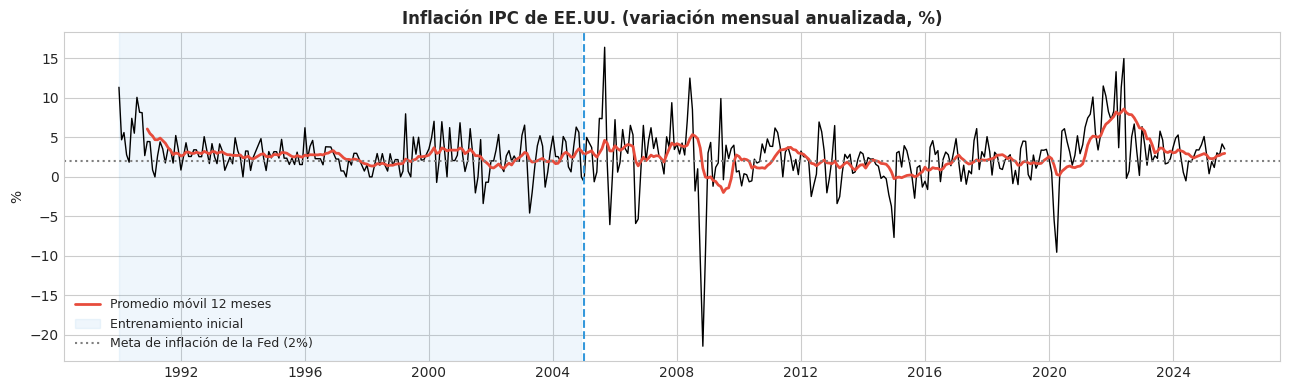

Entrenamiento inicial: 180 meses (1990-01 a 2004-12)
Evaluación fuera de muestra: 249 meses (2005-01 a 2025-09)
Razón p/n en el entrenamiento inicial: 90/180 = 0.50


In [6]:
# Inflación mensual anualizada y partición temporal
inicio_oos = df_model.index.get_loc(pd.Timestamp("2005-01-01"))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df_model.index, df_model[y_col], color="black", lw=1)
ax.plot(df_model.index, df_model[y_col].rolling(12).mean(), color="#e74c3c", lw=2, label="Promedio móvil 12 meses")
ax.axvspan(df_model.index[0], df_model.index[inicio_oos - 1], color="#3498db", alpha=0.08, label="Entrenamiento inicial")
ax.axvline(df_model.index[inicio_oos], color="#3498db", ls="--")
ax.axhline(2, color="gray", ls=":", label="Meta de inflación de la Fed (2%)")
ax.set_title("Inflación IPC de EE.UU. (variación mensual anualizada, %)", fontweight="bold")
ax.set_ylabel("%")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

print(f"Entrenamiento inicial: {inicio_oos} meses ({df_model.index[0]:%Y-%m} a {df_model.index[inicio_oos - 1]:%Y-%m})")
print(f"Evaluación fuera de muestra: {len(df_model) - inicio_oos} meses ({df_model.index[inicio_oos]:%Y-%m} a {df_model.index[-1]:%Y-%m})")
print(f"Razón p/n en el entrenamiento inicial: {len(X_cols)}/{inicio_oos} = {len(X_cols) / inicio_oos:.2f}")

## 3. Diagnóstico: ¿Por qué falla MCO con 90 Predictores?

Antes de aplicar Ridge o Lasso, evaluamos qué le sucede a Mínimos Cuadrados Ordinarios (MCO) al enfrentar una alta dimensionalidad ($p = 90$ predictores frente a solo $n \approx 180$ meses de entrenamiento entre 1990 y 2004).

Analizamos tres alertas metodológicas principales:

- Brecha entre $R^2$ y $R^2$ Ajustado: Un $R^2$ inflado artificialmente por la cantidad de variables, mientras que el $R^2$ ajustado descuenta el exceso de ruido.
- Rango Matricial ($\text{rank}(X)$): Indica cuántas columnas aportan información matemáticamente independiente. Si $\text{rank}(X) < p$, existen variables duplicadas o combinaciones lineales exactas (colinealidad perfecta).
- Número de Condición ($\kappa$): Mide la inestabilidad del sistema al invertir la matriz $X'X$. Un valor superior a 30 señala problemas de multicolinealidad; un valor que supera $10^3$ indica que MCO es incapaz de aislar el efecto individual de cada predictor.

In [7]:
# Muestra de entrenamiento inicial (1990–2004)
train_df = df_model.iloc[:inicio_oos]
y_train = train_df[y_col].values
X_train = train_df[X_cols].values
X_train_std = StandardScaler().fit_transform(X_train)

mod_ols = sm.OLS(y_train, sm.add_constant(X_train_std)).fit(cov_type="HAC", cov_kwds={"maxlags": 12})

diagnostico = pd.Series({
    "Observaciones (n)": mod_ols.nobs,
    "Predictores (p)": len(X_cols),
    "Razón p/n": len(X_cols) / mod_ols.nobs,
    "R2 in-sample (%)": mod_ols.rsquared * 100,
    "R2 ajustado (%)": mod_ols.rsquared_adj * 100,
    "Rango de X (columnas linealmente independientes)": np.linalg.matrix_rank(X_train_std),
    "Número de condición (X estandarizada)": np.linalg.cond(X_train_std),
})
display(diagnostico.to_frame("Valor").style.format("{:,.3g}"))

,Valor
Observaciones (n),180
Predictores (p),90
Razón p/n,0.5
R2 in-sample (%),68.4
R2 ajustado (%),39.8
Rango de X (columnas linealmente independientes),85
Número de condición (X estandarizada),1.66e+16


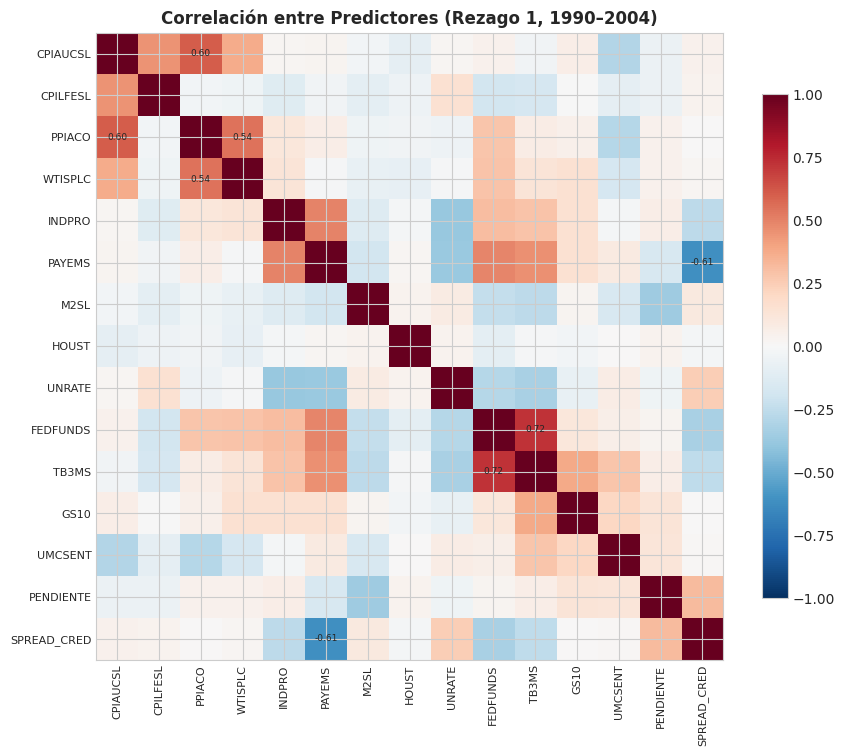


Pares de predictores con mayor correlación absoluta:


,,Correlación
PENDIENTE_lag5,PENDIENTE_lag6,0.979
PENDIENTE_lag4,PENDIENTE_lag5,0.979
PENDIENTE_lag3,PENDIENTE_lag4,0.978
PENDIENTE_lag2,PENDIENTE_lag3,0.978
PENDIENTE_lag1,PENDIENTE_lag2,0.978
SPREAD_CRED_lag5,SPREAD_CRED_lag6,0.955
SPREAD_CRED_lag4,SPREAD_CRED_lag5,0.955
SPREAD_CRED_lag3,SPREAD_CRED_lag4,0.955


In [8]:
# Correlaciones entre los primeros rezagos de las 15 series (entrenamiento inicial)
lag1_cols = [c for c in X_cols if c.endswith("_lag1")]
corr_lag1 = train_df[lag1_cols].corr()
etiquetas = [c.replace("_lag1", "") for c in lag1_cols]

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr_lag1.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(etiquetas))); ax.set_xticklabels(etiquetas, rotation=90, fontsize=8)
ax.set_yticks(range(len(etiquetas))); ax.set_yticklabels(etiquetas, fontsize=8)
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        if i != j and abs(corr_lag1.values[i, j]) >= 0.5:
            ax.text(j, i, f"{corr_lag1.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
ax.set_title("Correlación entre Predictores (Rezago 1, 1990–2004)", fontweight="bold")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

# Pares con mayor correlación absoluta entre los 90 predictores
corr_full = train_df[X_cols].corr()
pares = corr_full.where(np.triu(np.ones(corr_full.shape, dtype=bool), k=1)).stack()
top_corr = pares.reindex(pares.abs().sort_values(ascending=False).index).head(8).to_frame("Correlación")

print("\nPares de predictores con mayor correlación absoluta:")
display(top_corr.round(3))

### 3.1. Verificación de Redundancia Exacta (Identidad Financiera)

El rango de $X$ es 85, no 90: existen 5 columnas redundantes que son combinación lineal exacta de otras.Por construcción de la base, definimos la pendiente de la curva de rendimientos como:$$\text{PENDIENTE}_t = \text{GS10}_t - \text{TB3MS}_t$$Al tomar las diferencias para estandarizar las series, se genera la identidad:$$\Delta \text{PENDIENTE}_t = \Delta \text{GS10}_t - \Delta \text{TB3MS}_t$$Incluir la pendiente junto con la tasa corta (TB3MS) y la tasa larga (GS10) fuerza una colinealidad perfecta en cada rezago ($5 \text{ rezagos} \times 1 \text{ identidad} = 5 \text{ columnas redundantes}$). MCO no puede asignar un coeficiente único a cada variable, provocando que $(X'X)^{-1}$ se vuelva indeterminado o numéricamente inestable.

In [9]:
# Verificación: cambio de la pendiente = cambio de la tasa a 10 años − cambio de la tasa a 3 meses
k = 1
cambio_pendiente = train_df[f"PENDIENTE_lag{k}"] - train_df[f"PENDIENTE_lag{k+1}"]
cambio_tasas = train_df[f"GS10_lag{k}"] - train_df[f"TB3MS_lag{k}"]

display(pd.DataFrame({"Cambio en la pendiente": cambio_pendiente,
                      "Cambio 10 años − cambio 3 meses": cambio_tasas}).head().round(3))
print(f"Diferencia máxima entre ambas columnas: {(cambio_pendiente - cambio_tasas).abs().max():.1e} ")
print(f"Predictores sin información propia: {len(X_cols) - np.linalg.matrix_rank(X_train_std)}")


,Cambio en la pendiente,Cambio 10 años − cambio 3 meses
observation_date,,
1990-01-01,0.03,0.03
1990-02-01,0.36,0.36
1990-03-01,0.16,0.16
1990-04-01,-0.04,-0.04
1990-05-01,0.33,0.33


Diferencia máxima entre ambas columnas: 4.4e-16 
Predictores sin información propia: 5


> **Interpretación Económica:**
> 1. **MCO "memoriza":** explica el $68\%$ de la inflación dentro de muestra, pero el $R^2$ ajustado cae a $40\%$. Casi la mitad del ajuste se debe solo a tener 90 variables.
> 2. **Información duplicada:** por la identidad de la pendiente, MCO no puede separar los efectos de las tasas de interés, y sus coeficientes individuales no tienen interpretación (por eso ni siquiera miramos sus p-values). El número de condición, del orden de $10^{16}$, lo confirma.
> 3. **Variables que se mueven juntas:** fondos federales y letra a 3 meses ($0.72$), precios al productor e IPC ($0.60$), empleo y spread de crédito ($-0.61$).
>
> **Idea clave:** la regularización resuelve este problema. La penalización de Ridge le da a la estimación un criterio para repartir el efecto entre variables parecidas, y Lasso simplemente se queda con una de ellas.

## 4. La Regularización en Acción

¿Qué les pasa a los coeficientes cuando aumentamos la penalización $\lambda$? Usando el entrenamiento inicial (1990–2004):

- Ridge (Izquierda): Achica el tamaño de todas las variables al mismo tiempo, pero sin borrar ninguna.
- Lasso (Centro): Va apagando variables una por una (las deja en cero) a medida que sube la penalización.
- Elegir la Penalización (Derecha): Si no penalizamos (izquierda), el error es alto por sobreajuste. Si penalizamos demasiado (derecha), el modelo no aprende nada. El mejor $\lambda$ es el punto más bajo de la curva (línea roja).

La línea negra destaca el rezago de la propia inflación (`CPIAUCSL_lag1`).

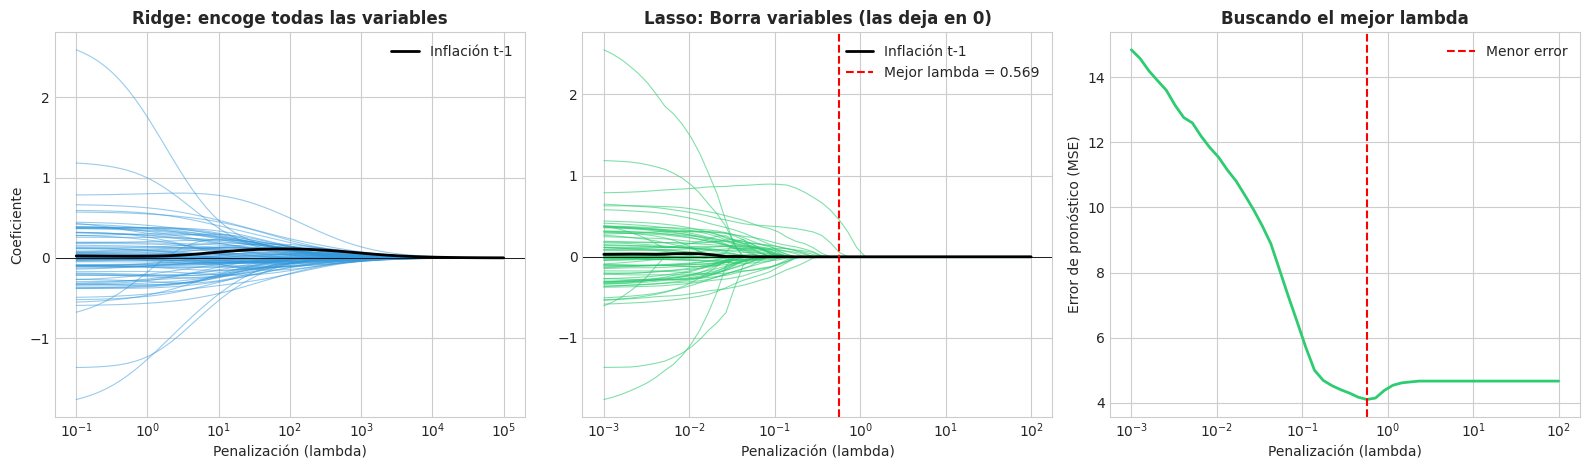

Mejor lambda: 0.5690
Variables elegidas por Lasso (2 de 90): ['CPILFESL_lag3', 'WTISPLC_lag1']
MSE de validación: lambda casi cero = 14.84; lambda elegido = 4.10; solo constante (lambda máximo) = 4.66
Meses de entrenamiento en cada bloque de validación: [30, 60, 90, 120, 150]


In [10]:
# Trayectorias de coeficientes en el entrenamiento inicial
tscv = TimeSeriesSplit(n_splits=5)
X_tr_std = StandardScaler().fit_transform(X_train)
y_tr_c = y_train - y_train.mean()

grilla_lasso = np.logspace(-3, 2, 50)   # misma grilla que en el walk-forward (sección 5)
grilla_ridge = np.logspace(-1, 5, 60)

lambdas_lasso, coefs_lasso, _ = lasso_path(X_tr_std, y_tr_c, alphas=grilla_lasso)
coefs_ridge = np.array([Ridge(alpha=l).fit(X_tr_std, y_tr_c).coef_ for l in grilla_ridge])
lasso_tr = LassoCV(alphas=grilla_lasso, cv=tscv, max_iter=50000).fit(X_tr_std, y_train)

j_destacado = X_cols.index("CPIAUCSL_lag1")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Ridge
axes[0].plot(grilla_ridge, coefs_ridge, color="#3498db", lw=0.8, alpha=0.5)
axes[0].plot(grilla_ridge, coefs_ridge[:, j_destacado], color="black", lw=2, label="Inflación t-1")
axes[0].set_xscale("log")
axes[0].axhline(0, color="black", lw=0.6)
axes[0].set_title("Ridge: encoge todas las variables", fontweight="bold")
axes[0].set_xlabel("Penalización (lambda)")
axes[0].set_ylabel("Coeficiente")
axes[0].legend()

# 2. Lasso
axes[1].plot(lambdas_lasso, coefs_lasso.T, color="#2ecc71", lw=0.8, alpha=0.6)
axes[1].plot(lambdas_lasso, coefs_lasso[j_destacado], color="black", lw=2, label="Inflación t-1")
axes[1].axvline(lasso_tr.alpha_, color="red", ls="--", label=f"Mejor lambda = {lasso_tr.alpha_:.3f}")
axes[1].set_xscale("log")
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set_title("Lasso: Borra variables (las deja en 0)", fontweight="bold")
axes[1].set_xlabel("Penalización (lambda)")
axes[1].legend()

# 3. Error de validación
mse_media = lasso_tr.mse_path_.mean(axis=1)
axes[2].plot(lasso_tr.alphas_, mse_media, color="#2ecc71", lw=2)
axes[2].axvline(lasso_tr.alpha_, color="red", ls="--", label="Menor error")
axes[2].set_xscale("log")
axes[2].set_title("Buscando el mejor lambda", fontweight="bold")
axes[2].set_xlabel("Penalización (lambda)")
axes[2].set_ylabel("Error de pronóstico (MSE)")
axes[2].legend()

plt.tight_layout()
plt.show()

# Resumen de variables seleccionadas
no_nulos = [X_cols[i] for i in np.flatnonzero(np.abs(lasso_tr.coef_) > 1e-8)]
print(f"Mejor lambda: {lasso_tr.alpha_:.4f}")
print(f"Variables elegidas por Lasso ({len(no_nulos)} de {len(X_cols)}): {no_nulos}")
print(f"MSE de validación: lambda casi cero = {mse_media[-1]:.2f}; lambda elegido = {mse_media.min():.2f}; solo constante (lambda máximo) = {mse_media[0]:.2f}")
print(f"Meses de entrenamiento en cada bloque de validación: {[len(tr) for tr, _ in tscv.split(X_train)]}")

> **Interpretación de los Gráficos:**
>
> 1. **Ridge encoge, Lasso selecciona:** Ridge mantiene los 90 predictores, cada vez con menos fuerza; Lasso los va apagando uno a uno.
> 2. **Lasso se queda con muy poco:** con el mejor $\lambda$ ($0.569$) descarta 88 variables y conserva solo 2: la inflación subyacente de hace tres meses y el precio del petróleo del mes anterior.
> 3. **Cuidado con el "error sin penalización":** con $\lambda$ casi cero el error de validación es $14.8$, pero esa cifra exagera el problema: el primer bloque de validación entrena con solo 30 meses para estimar 90 coeficientes, una regresión que no tiene solución única. La comparación justa es contra el modelo que solo usa la media ($\lambda$ máximo): el error baja de $4.66$ a $4.10$, una mejora de $12\%$. **Útil, pero modesta:** gran parte de la inflación mensual es ruido difícil de anticipar.

### Coeficientes de la Regresión

Antes de pronosticar, miremos los coeficientes de cada modelo con su **$\lambda$ óptimo**, estimados con los datos de 1990–2004. 


- **Unidades estandarizadas:** como los predictores están en $Z$-score, el coeficiente indica cuántos puntos porcentuales cambia la inflación pronosticada cuando el predictor sube **una desviación estándar**. Así podemos comparar variables con unidades distintas (petróleo vs. desempleo).
- **Unidades originales:** dividiendo por la desviación estándar del predictor volvemos a sus unidades. Por ejemplo, "cuánto sube la inflación si el petróleo sube 1 punto".
- **Están encogidos a propósito:** la penalización empuja los coeficientes hacia cero. Su **signo** y su **orden de importancia** son informativos, pero su **magnitud subestima** el efecto. Corregir esto es la idea de *Post-Lasso* (U4-04).
- **No son causales:** un coeficiente distinto de cero dice que la variable **ayuda a predecir**, no que cause la inflación.
- **MCO no aparece:** con información duplicada (sección 3.1) sus coeficientes no tienen una solución única y no se pueden interpretar.

In [11]:
# AR(1) por MCO, llevado a la misma escala (coeficiente × desviación estándar del rezago)
j_ar = X_cols.index("CPIAUCSL_lag1")
ar1_tr = sm.OLS(y_train, sm.add_constant(X_train[:, j_ar])).fit()
sd_x = X_train.std(axis=0)

print(ar1_tr.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.073
Model:                            OLS   Adj. R-squared:                  0.067
Method:                 Least Squares   F-statistic:                     13.95
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           0.000253
Time:                        12:55:26   Log-Likelihood:                -389.35
No. Observations:                 180   AIC:                             782.7
Df Residuals:                     178   BIC:                             789.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.0232      0.257      7.867      0.0

In [12]:
# Regresión óptima de cada modelo en el entrenamiento inicial (1990–2004), con las mismas grillas del walk-forward
grilla = np.logspace(-3, 2, 50)
optimos = {
    "Ridge (L2)":  make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 5, 50), cv=tscv)),
    "Lasso (L1)":  make_pipeline(StandardScaler(), LassoCV(alphas=grilla, cv=tscv, max_iter=20000)),
    "Elastic Net": make_pipeline(StandardScaler(), ElasticNetCV(alphas=grilla, l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9], cv=tscv, max_iter=20000)),
}
for modelo in optimos.values():
    modelo.fit(X_train, y_train)

# Coeficientes estandarizados de cada modelo (el AR(1) se lleva a la misma escala)
coef_std = pd.DataFrame({n: m[-1].coef_ for n, m in optimos.items()}, index=X_cols)
coef_std.insert(0, "AR(1)", 0.0)
coef_std.loc["CPIAUCSL_lag1", "AR(1)"] = ar1_tr.params[1] * sd_x[j_ar]



# Resumen de cada regresión óptima
resumen = pd.DataFrame({
    "lambda óptimo": [np.nan] + [m[-1].alpha_ for m in optimos.values()],
    "Mezcla L1 (l1_ratio)": [np.nan, 0.0, 1.0, optimos["Elastic Net"][-1].l1_ratio_],
    "Coeficientes distintos de cero": (coef_std.abs() > 1e-8).sum().values,
    "Constante (media de inflación)": [ar1_tr.params[0]] + [m[-1].intercept_ for m in optimos.values()],
}, index=coef_std.columns)
print("Resumen de cada regresión óptima (entrenamiento 1990–2004):")
display(resumen.round(4))



Resumen de cada regresión óptima (entrenamiento 1990–2004):


,lambda óptimo,Mezcla L1 (l1_ratio),Coeficientes distintos de cero,Constante (media de inflación)
AR(1),NaN,NaN,1,2.0232
Ridge (L2),100000.000,0.0,90,2.7818
Lasso (L1),0.569,1.0,2,2.7818
Elastic Net,0.569,0.9,2,2.7818


In [13]:
# Variables que importan: las elegidas por Lasso o Elastic Net, más las 5 más grandes de Ridge
filas = coef_std.index[(coef_std[["Lasso (L1)", "Elastic Net"]].abs() > 1e-8).any(axis=1)].tolist()
filas += coef_std["Ridge (L2)"].abs().sort_values(ascending=False).index[:5].tolist()
filas = list(dict.fromkeys(["CPIAUCSL_lag1"] + filas))
print("\nCoeficientes estandarizados (puntos porcentuales de inflación por cada desviación estándar del predictor):")
display(coef_std.loc[filas].round(3) + 0.0)


Coeficientes estandarizados (puntos porcentuales de inflación por cada desviación estándar del predictor):


,AR(1),Ridge (L2),Lasso (L1),Elastic Net
CPIAUCSL_lag1,0.589,0.001,0.000,0.000
CPILFESL_lag3,0.000,0.001,0.053,0.104
WTISPLC_lag1,0.000,0.002,0.455,0.484
PPIACO_lag1,0.000,0.001,0.000,0.000
GS10_lag5,0.000,0.001,0.000,0.000


In [14]:
# Unidades originales para las variables elegidas por Lasso
elegidas = coef_std.index[coef_std["Lasso (L1)"].abs() > 1e-8]
orig = pd.DataFrame({
    "Desv. estándar del predictor": sd_x[[X_cols.index(v) for v in elegidas]],
    "Coef. Lasso estandarizado": coef_std.loc[elegidas, "Lasso (L1)"].values,
}, index=elegidas)
orig["Coef. Lasso en unidades originales"] = orig["Coef. Lasso estandarizado"] / orig["Desv. estándar del predictor"]
print("\nLasso en unidades originales:")
display(orig.round(4))
print(f"AR(1) en unidades originales: inflación_t = {ar1_tr.params[0]:.2f} + {ar1_tr.params[1]:.2f} × inflación_(t-1)")
print(f"Desviación estándar de la inflación en el entrenamiento: {y_train.std():.2f} pp")


Lasso en unidades originales:


,Desv. estándar del predictor,Coef. Lasso estandarizado,Coef. Lasso en unidades originales
CPILFESL_lag3,1.4277,0.0534,0.0374
WTISPLC_lag1,95.7119,0.4546,0.0047


AR(1) en unidades originales: inflación_t = 2.02 + 0.27 × inflación_(t-1)
Desviación estándar de la inflación en el entrenamiento: 2.19 pp


> **Interpretación de los Coeficientes:**
>
> 1. **AR(1):** $\hat{\pi}_t = 2.02 + 0.27\,\pi_{t-1}$. Si la inflación del mes pasado fue 1 punto más alta, se pronostica $0.27$ puntos más este mes: hay inercia, pero se disipa rápido. En unidades estandarizadas, el efecto es $0.59$ pp por cada desviación estándar.
> 2. **Ridge es casi la media histórica:** su $\lambda$ quedó en el **máximo de la grilla** ($100.000$) y todos los coeficientes valen alrededor de $0.001$. Para silenciar las 88 variables que no aportan, Ridge tuvo que silenciar también a las 2 que sí aportan, porque no puede apagar solo algunas. Su pronóstico es prácticamente la constante ($2.78\%$).
> 3. **Lasso: petróleo y núcleo inflacionario.** El coeficiente del petróleo en unidades originales es $0.0047$: si el WTI sube $10\%$ en un mes (cerca de $120$ puntos anualizados), Lasso pronostica $0.56$ puntos más de inflación anualizada al mes siguiente. Es el traspaso rápido de la energía al IPC, vía gasolina. La inflación subyacente aporta poco ($0.05$ pp por desviación estándar).
> 4. **¿Por qué Lasso no usa la inflación del mes pasado?** Porque compite con variables que se le parecen: el petróleo del mes pasado se mueve con ella (correlación $0.37$) y anticipa la parte más volátil del IPC, la energía. Con un "presupuesto" limitado de coeficientes, Lasso se queda con la que más reduce el error y apaga la otra. **Que un coeficiente sea cero no significa que la variable no importe**; significa que, para predecir, otras variables ya hacen buena parte de ese trabajo.
> 5. **Elastic Net ≈ Lasso:** eligió una mezcla de $90\%$ Lasso y $10\%$ Ridge, y conserva las mismas 2 variables con coeficientes algo mayores ($0.10$ y $0.48$).
> 6. **Las magnitudes están encogidas:** si estimamos MCO solo con esas 2 variables, los coeficientes estandarizados son $0.62$ (subyacente) y $1.02$ (petróleo), frente a $0.05$ y $0.46$ de Lasso: la penalización los dejó en menos de la mitad. Para pronosticar eso no es un problema (es justamente lo que reduce la varianza), pero si queremos **medir** el efecto del petróleo debemos re-estimar sin penalización sobre las variables elegidas (*Post-Lasso*, U4-04).

## 5. Pronóstico Fuera de Muestra (*Walk-Forward*)

Simulamos la labor de un analista desde 2005 hasta 2025: cada mes pronostica la inflación del mes siguiente usando únicamente la información disponible hasta ese momento.

Estrategia de Evaluación

- Ventana expansiva: Se inicia con la muestra 1990–2004.
- Re-estimación anual: Cada 12 meses se vuelven a estimar los modelos y se ajusta el hiperparámetro de penalización ($\lambda$) mediante validación cruzada temporal (`TimeSeriesSplit`), incorporando la información reciente sin sesgo de anticipación (look-ahead bias).

Modelos que compiten:

| Modelo | Pronóstico | Idea |
|---|---|---|
| **Random Walk** | Inflación del mes pasado | Benchmark simple (ingenuo)|
| **Media Histórica** | Promedio de toda la historia | Benchmark de retorno a la media|
| **AR(1)** | $\hat{c} + \hat{\phi}\,\pi_{t-1}$ | Inercia de la inflación |
| **MCO (90 predictores)** | MCO sin penalización | Modelo sin regularizar (overfitting) |
| **Ridge, Lasso, Elastic Net** | 90 predictores con selección de $\lambda$ por validación cruzada| Modelos regularizados|


In [15]:
def pronostico_walk_forward(y, X, inicio, paso, col_ar, pred_rw, nombres, fechas, n_splits=5):
    """Pronóstico un paso adelante con ventana expansiva, re-estimando cada `paso` observaciones.

    y, X     : arreglos con la variable objetivo y los predictores (ya rezagados).
    inicio   : índice de la primera observación fuera de muestra.
    col_ar   : columna de X que contiene el primer rezago de y (para el AR(1)).
    pred_rw  : pronóstico Random Walk para el período fuera de muestra.
    """
    tscv = TimeSeriesSplit(n_splits=n_splits)
    grilla = np.logspace(-3, 2, 50)
    modelos = {
        "MCO (todos)": lambda: make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge (L2)":  lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 5, 50), cv=tscv)),
        "Lasso (L1)":  lambda: make_pipeline(StandardScaler(), LassoCV(alphas=grilla, cv=tscv, max_iter=20000)),
        "Elastic Net": lambda: make_pipeline(StandardScaler(), ElasticNetCV(alphas=grilla, l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9],cv=tscv, max_iter=20000)),
    }
    T = len(y) - inicio

    pred = {"Random Walk": np.asarray(pred_rw, dtype=float), 
            "Media Histórica": np.full(T, np.nan), 
            "AR(1)": np.full(T, np.nan)}

    pred.update({nombre: np.full(T, np.nan) for nombre in modelos})
    coefs = {"Lasso (L1)": [], "Elastic Net": []}
    hiper = []

    for s in range(inicio, len(y), paso):
        e = min(s + paso, len(y))
        bloque = slice(s - inicio, e - inicio)

        # Benchmarks estimados solo con información hasta s-1
        pred["Media Histórica"][bloque] = y[:s].mean()
        ar1 = sm.OLS(y[:s], sm.add_constant(X[:s, col_ar])).fit()
        pred["AR(1)"][bloque] = ar1.params[0] + ar1.params[1] * X[s:e, col_ar]

        # Modelos regularizados y MCO con todos los predictores
        ajustados = {}
        for nombre, crear in modelos.items():
            ajustados[nombre] = crear().fit(X[:s], y[:s])
            pred[nombre][bloque] = ajustados[nombre].predict(X[s:e])
        for nombre in coefs:
            coefs[nombre].append(pd.Series(ajustados[nombre][-1].coef_, index=nombres, name=fechas[s]))

        # Hiperparámetros elegidos por validación cruzada en esta re-estimación
        hiper.append({"Fecha": fechas[s],
                      "lambda Ridge": ajustados["Ridge (L2)"][-1].alpha_,
                      "lambda Lasso": ajustados["Lasso (L1)"][-1].alpha_,
                      "lambda EN": ajustados["Elastic Net"][-1].alpha_,
                      "alpha EN (l1_ratio)": ajustados["Elastic Net"][-1].l1_ratio_})

    pred_df = pd.DataFrame(pred, index=fechas[inicio:])
    coefs_df = {k: pd.DataFrame(v) for k, v in coefs.items()}
    hiper_df = pd.DataFrame(hiper).set_index("Fecha")
    
    return pred_df, coefs_df, hiper_df

In [16]:
# Ejecución del esquema walk-forward
y_all = df_model[y_col].values
X_all = df_model[X_cols].values
col_ar = X_cols.index("CPIAUCSL_lag1")
pred_rw = X_all[inicio_oos:, col_ar]

pred_oos, coefs_oos, hiper_oos = pronostico_walk_forward(
    y_all, X_all, inicio=inicio_oos, paso=12, col_ar=col_ar,
    pred_rw=pred_rw, nombres=X_cols, fechas=df_model.index
)

y_test = pd.Series(y_all[inicio_oos:], index=pred_oos.index)
print(f"Re-estimaciones realizadas: {len(hiper_oos)}  (lambda elegido por validación cruzada en cada una)")
display(hiper_oos.round(4))

Re-estimaciones realizadas: 21  (lambda elegido por validación cruzada en cada una)


,lambda Ridge,lambda Lasso,lambda EN,alpha EN (l1_ratio)
Fecha,,,,
2005-01-01,100000.0000,0.5690,0.5690,0.9
2006-01-01,100000.0000,0.5690,0.5690,0.9
2007-01-01,100000.0000,0.3556,0.4498,0.9
2008-01-01,100000.0000,0.4498,0.4498,0.9
2009-01-01,100000.0000,0.3556,0.3556,0.9
2010-01-01,100000.0000,0.3556,0.3556,0.9
2011-01-01,1930.6977,0.2812,0.2812,0.9
2012-01-01,1000.0000,0.2223,0.2812,0.9
2013-01-01,3727.5937,0.2812,0.3556,0.9


### 5.1. Los Pronósticos Obtenidos

La tabla anterior muestra **qué lambda eligió** cada modelo en cada re-estimación, pero los pronósticos ya están calculados: quedaron guardados en `pred_oos`. Este DataFrame tiene **una fila por mes** entre enero de 2005 y septiembre de 2025 (249 meses) y **una columna por modelo**.

Comparamos los últimos 12 pronósticos con la inflación que efectivamente ocurrió:

In [17]:
# Últimos 12 pronósticos fuera de muestra junto a la inflación observada (% anualizado)
pronosticos = pd.concat([y_test.rename("Inflación observada"), pred_oos], axis=1)
print(f"Pronósticos fuera de muestra: {pred_oos.shape[0]} meses × {pred_oos.shape[1]} modelos")
display(pronosticos.tail(12).round(2))

Pronósticos fuera de muestra: 249 meses × 7 modelos


,Inflación observada,Random Walk,Media Histórica,AR(1),MCO (todos),Ridge (L2),Lasso (L1),Elastic Net
observation_date,,,,,,,,
2024-10-01,3.42,2.56,2.63,2.59,0.40,1.02,0.78,0.81
2024-11-01,3.41,3.42,2.63,2.99,2.30,2.66,2.63,2.62
2024-12-01,4.07,3.41,2.63,2.99,1.17,2.48,2.26,2.30
2025-01-01,5.12,4.07,2.63,3.30,1.69,2.10,2.52,2.60
2025-02-01,2.70,5.12,2.63,3.79,5.29,5.16,4.99,4.77
2025-03-01,0.40,2.70,2.63,2.66,3.79,3.25,2.76,2.77
2025-04-01,1.94,0.40,2.63,1.60,2.74,2.22,1.65,1.65
2025-05-01,1.19,1.94,2.63,2.31,1.91,2.29,2.57,2.50
2025-06-01,3.05,1.19,2.63,1.97,4.37,3.34,2.91,2.76


> **Interpretación:**
> 1. **El Random Walk siempre llega tarde:** su pronóstico es la inflación del mes anterior. Cuando la inflación sube a $5.1\%$ en enero de 2025, el Random Walk lo "pronostica" recién en febrero, justo cuando bajó a $2.7\%$.
> 2. **El AR(1) es un Random Walk suavizado:** parte de la inflación del mes pasado, pero la acerca a la media histórica ($2.6\%$). Por eso se equivoca menos en los saltos.
> 3. **Lasso y Elastic Net se equivocan en los meses clave del final de la muestra:** en octubre de 2024 pronosticaron $0.8\%$ cuando la inflación fue $3.4\%$, y en septiembre de 2025, $1.8\%$ frente a $3.5\%$. Es el costo de haber aprendido una relación fuerte con la energía (sección 6.3).


### 5.2. Pronóstico para el Próximo Mes

Los 249 pronósticos anteriores sirven para **evaluar** los modelos: simulan lo que habría hecho un analista en el pasado. Pero un analista real quiere saber **qué pasará el próximo mes**. Para eso:

1. **Re-estimamos cada modelo con toda la muestra** (1990 a septiembre de 2025), eligiendo nuevamente lambda por validación cruzada.
2. **Armamos los predictores del mes siguiente:** los últimos 6 meses observados de cada una de las 15 series (rezagos 1 a 6), con el mismo orden que usamos para estimar.
3. **Aplicamos cada modelo** a esos predictores.

> **Nota:** la muestra termina en septiembre de 2025, por lo que el pronóstico es para **octubre de 2025**.

In [18]:
# Pronóstico para el mes siguiente al final de la muestra
fecha_pron = df_model.index[-1] + pd.DateOffset(months=1)

# Predictores del próximo mes: rezago 1 = último mes observado, rezago 6 = seis meses atrás (mismo orden que X_cols)
x_prox = np.array([[macro[col].iloc[-lag] for col in macro.columns for lag in lags]])
assert macro.index[-1] == df_model.index[-1] and not np.isnan(x_prox).any()

# Benchmarks
pron_final = {"Random Walk": x_prox[0, col_ar], "Media Histórica": y_all.mean()}
ar1_final = sm.OLS(y_all, sm.add_constant(X_all[:, col_ar])).fit()
pron_final["AR(1)"] = ar1_final.params[0] + ar1_final.params[1] * x_prox[0, col_ar]

# MCO y modelos regularizados, re-estimados con toda la muestra (mismas grillas del walk-forward)
grilla = np.logspace(-3, 2, 50)
modelos_finales = {
    "MCO (todos)": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (L2)":  make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 5, 50), cv=tscv)),
    "Lasso (L1)":  make_pipeline(StandardScaler(), LassoCV(alphas=grilla, cv=tscv, max_iter=20000)),
    "Elastic Net": make_pipeline(StandardScaler(), ElasticNetCV(alphas=grilla, l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9], cv=tscv, max_iter=20000)),
}
lambda_final = {}
for nombre, modelo in modelos_finales.items():
    modelo.fit(X_all, y_all)
    pron_final[nombre] = modelo.predict(x_prox)[0]
    lambda_final[nombre] = getattr(modelo[-1], "alpha_", np.nan)

tabla_pron = pd.DataFrame({
    f"Pronóstico {fecha_pron:%Y-%m} (% anualizado)": pd.Series(pron_final),
    "lambda elegido": pd.Series(lambda_final),
}).reindex(pron_final.keys())   # mantiene el orden de los modelos
print(f"Último dato observado ({df_model.index[-1]:%Y-%m}): inflación = {y_all[-1]:.2f}% anualizado")
display(tabla_pron.round(3))

Último dato observado (2025-09): inflación = 3.54% anualizado


,Pronóstico 2025-10 (% anualizado),lambda elegido
Random Walk,3.536,NaN
Media Histórica,2.637,NaN
AR(1),3.053,NaN
MCO (todos),0.554,NaN
Ridge (L2),1.479,138.950
Lasso (L1),2.007,0.139
Elastic Net,2.112,0.176


> **Interpretación:**
> 1. **Los modelos no coinciden:** con una inflación de $3.5\%$ en septiembre de 2025, los pronósticos para octubre van de $0.6\%$ (MCO) a $3.5\%$ (Random Walk). El AR(1) pronostica $3.1\%$ porque la inercia se disipa hacia la media. Lasso ($2.0\%$), Elastic Net ($2.1\%$) y Ridge ($1.5\%$) pronostican una caída mayor: los indicadores de los últimos seis meses apuntan a menos inflación.


## 6. ¿Qué Modelo Pronostica Mejor?

### 6.1. Métricas

Usamos las mismas métricas de U4-02:

- **RMSE y MAE:** error típico de pronóstico, en puntos porcentuales de inflación. Menor es mejor.
- **$R^2_{oos}$:** cuánto reduce el modelo el error respecto de un benchmark. Un $R^2_{oos} = 10\%$ significa "10% menos error cuadrático que el benchmark"; un valor negativo significa que el modelo es peor. Lo calculamos frente al Random Walk y frente al AR(1).

### 6.2. Test de Significancia: Clark y West (2007)

Un modelo puede ganar por azar en un período particular. El test de **Clark y West (2007)** responde si la mejora es estadísticamente significativa.

Tiene un detalle importante: compara un modelo **grande** (90 predictores) con uno **pequeño** que está contenido en él (el AR(1)). El modelo grande parte con una desventaja injusta: aunque las variables extra no sirvieran, estimarlas agrega un poco de ruido al pronóstico. Clark-West corrige esa desventaja.

**Regla:** p-value $< 0.05$ → el modelo grande pronostica significativamente mejor que el benchmark.

In [19]:
def clark_west(y, f_bench, f_modelo, maxlags=12):
    """Test de Clark y West (2007) para comparación de modelos anidados."""
    f_cw = (y - f_bench)**2 - ((y - f_modelo)**2 - (f_bench - f_modelo)**2)
    reg = sm.OLS(f_cw, np.ones(len(f_cw))).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    t_stat = reg.tvalues[0]
    return t_stat, 1 - norm.cdf(t_stat)


def tabla_evaluacion(y, pred, maxlags=12):
    """Calcula errores cuadráticos, R2 fuera de muestra y p-values de Clark-West."""
    y = np.asarray(y)
    mspe = {k: np.mean((y - pred[k].values)**2) for k in pred}
    modelos_grandes = ["MCO (todos)", "Ridge (L2)", "Lasso (L1)", "Elastic Net"]
    
    filas = []
    for k in pred:
        p = pred[k].values
        cw_rw = clark_west(y, pred["Random Walk"].values, p, maxlags)[1] if k in modelos_grandes + ["AR(1)"] else np.nan
        cw_ar = clark_west(y, pred["AR(1)"].values, p, maxlags)[1] if k in modelos_grandes else np.nan
        
        filas.append({
            "Modelo": k,
            "RMSE": np.sqrt(mspe[k]),
            "MAE": np.mean(np.abs(y - p)),
            "R²_OOS vs RW (%)": (1 - mspe[k] / mspe["Random Walk"]) * 100,
            "R²_OOS vs AR(1) (%)": (1 - mspe[k] / mspe["AR(1)"]) * 100,
            "CW vs RW (p-val)": cw_rw,
            "CW vs AR(1) (p-val)": cw_ar,
        })
    return pd.DataFrame(filas).set_index("Modelo")

tabla_oos = tabla_evaluacion(y_test, pred_oos)

print("Inflación IPC de EE.UU., enero 2005 – septiembre 2025 (RMSE y MAE en puntos porcentuales anualizados)")
display(tabla_oos.round(3))


Inflación IPC de EE.UU., enero 2005 – septiembre 2025 (RMSE y MAE en puntos porcentuales anualizados)


,RMSE,MAE,R²_OOS vs RW (%),R²_OOS vs AR(1) (%),CW vs RW (p-val),CW vs AR(1) (p-val)
Modelo,,,,,,
Random Walk,3.801,2.630,0.000,-25.263,NaN,NaN
Media Histórica,3.846,2.533,-2.356,-28.214,NaN,NaN
AR(1),3.396,2.267,20.168,0.000,0.000,NaN
MCO (todos),6.070,3.339,-155.013,-219.437,0.007,0.054
Ridge (L2),3.601,2.406,10.288,-12.376,0.000,0.590
Lasso (L1),3.406,2.303,19.699,-0.588,0.000,0.032
Elastic Net,3.394,2.307,20.264,0.120,0.000,0.022


> **¿Cómo puede Lasso perder frente al AR(1) y aun así ser "significativo" en Clark-West?**
>
> Lasso tiene $R^2_{oos} = -0.6\%$ frente al AR(1), pero el test de Clark-West da $p = 0.03$. MCO es todavía más llamativo: $-219\%$ y $p = 0.054$. No es una contradicción: las dos medidas responden **preguntas distintas**.
>
> | Medida | Pregunta que responde | Lasso vs AR(1) |
> |---|---|---|
> | $R^2_{oos}$ | ¿El modelo, **tal como lo estimamos**, pronosticó mejor? | No ($-0.6\%$) |
> | Clark-West | ¿Las variables extra **contienen información** útil para predecir? | Sí ($p = 0.03$) |
>
> La diferencia entre ambas es el **ruido de estimación**: estimar muchos coeficientes con pocos datos agrega error al pronóstico, y Clark-West descuenta ese error (la "desventaja injusta" de la sección 6.2). Para Lasso, la lectura es: *los indicadores macro sí tienen información sobre la inflación futura, pero con 15–20 años de datos no alcanzamos a aprovecharla mejor que el AR(1).*
>
> **Regla práctica:** para **elegir qué modelo usar** mire el $R^2_{oos}$; para saber **si vale la pena seguir trabajando** con esas variables mire Clark-West.

### 6.3. Análisis por Subperíodos Históricos

Un buen resultado promedio puede esconder períodos en que el modelo falla. Calculamos el $R^2_{oos}$ frente al AR(1) en cada etapa de la muestra.

In [20]:
periodos = {
    "2005–2007 (Gran Moderación)": ("2005-01-01", "2007-12-01"),
    "2008–2009 (Crisis Financiera)": ("2008-01-01", "2009-12-01"),
    "2010–2019 (Inflación Baja)": ("2010-01-01", "2019-12-01"),
    "2020–2023 (Pandemia y Shocks)": ("2020-01-01", "2023-12-01"),
    "2024–2025 (Desinflación)": ("2024-01-01", "2025-09-01"),
}

filas_sub = []
for etiqueta, (a, b) in periodos.items():
    yy = y_test.loc[a:b]
    pp = pred_oos.loc[a:b]
    mspe_ar = np.mean((yy - pp["AR(1)"])**2)
    
    filas_sub.append({
        "Período": etiqueta, 
        "Meses": len(yy),
        **{f"R² vs AR(1): {k} (%)": (1 - np.mean((yy - pp[k])**2) / mspe_ar) * 100 
           for k in ["Ridge (L2)", "Lasso (L1)", "Elastic Net"]}
    })

display(pd.DataFrame(filas_sub).set_index("Período").round(2))

,Meses,R² vs AR(1): Ridge (L2) (%),R² vs AR(1): Lasso (L1) (%),R² vs AR(1): Elastic Net (%)
Período,,,,
2005–2007 (Gran Moderación),36,-7.03,2.70,3.21
2008–2009 (Crisis Financiera),24,-24.31,-8.67,-8.76
2010–2019 (Inflación Baja),120,-10.79,10.07,8.84
2020–2023 (Pandemia y Shocks),48,1.91,3.20,6.54
2024–2025 (Desinflación),21,-92.47,-84.82,-81.03


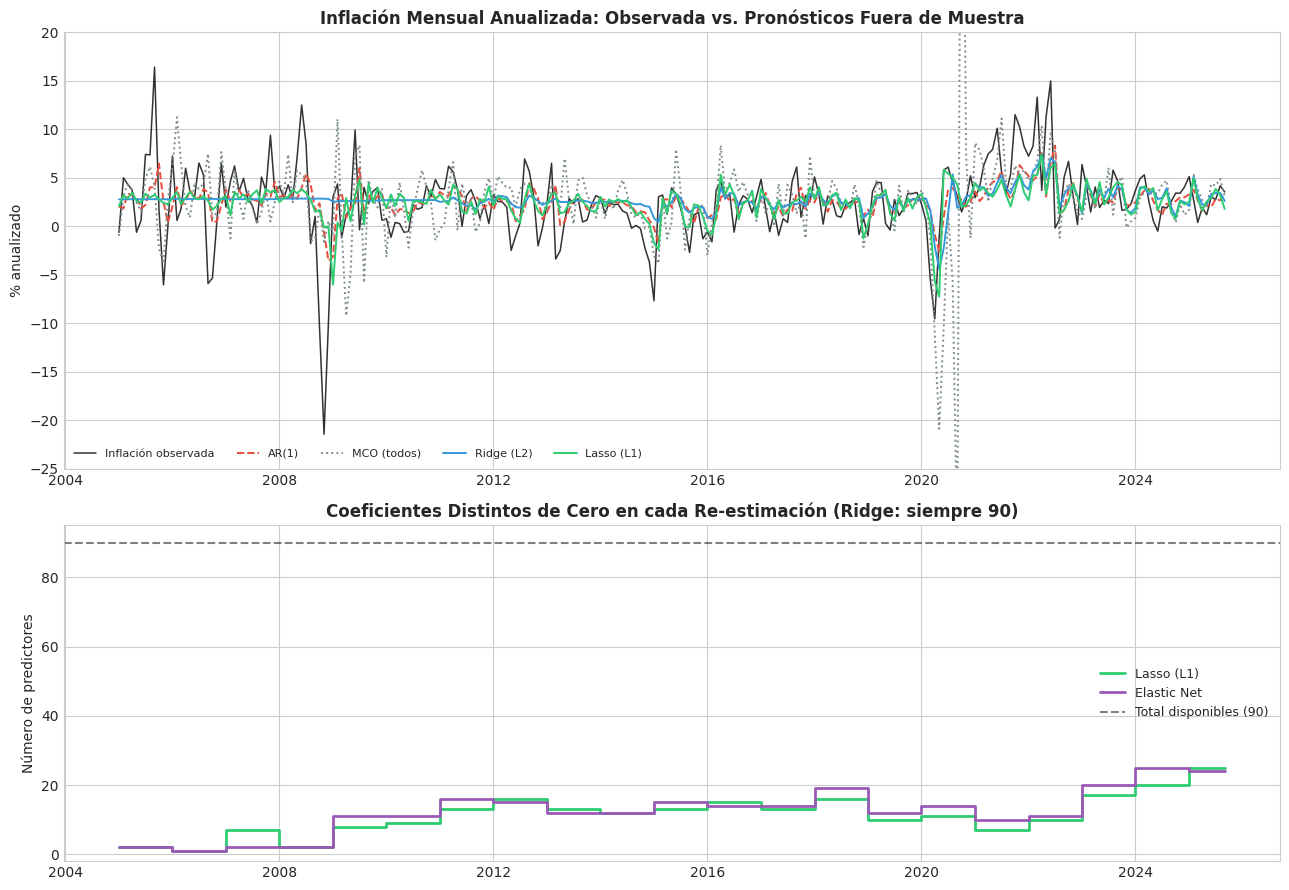

Pronóstico MCO (todos): máximo 60.4% (2020-10), mínimo -33.0% (2020-09)
Lasso mantuvo entre 1 y 25 coeficientes distintos de cero (de 90).


In [21]:
# Gráficos: pronósticos e intensidad de la regularización en el tiempo
fig, axes = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [1.3, 1]})

# Panel 1: inflación observada y pronósticos
axes[0].plot(y_test.index, y_test, color="black", lw=1.1, alpha=0.8, label="Inflación observada")
for nombre, estilo in [("AR(1)", "--"), ("MCO (todos)", ":"), ("Ridge (L2)", "-"), ("Lasso (L1)", "-")]:
    axes[0].plot(pred_oos.index, pred_oos[nombre], color=colores[nombre], lw=1.4, ls=estilo, label=nombre)
axes[0].set_ylim(-25, 20)   # MCO se sale de la escala en 2020 (ver valores impresos abajo)
axes[0].set_title("Inflación Mensual Anualizada: Observada vs. Pronósticos Fuera de Muestra", fontweight="bold")
axes[0].set_ylabel("% anualizado")
axes[0].legend(loc="lower left", fontsize=8, ncol=5)

# Panel 2: número de coeficientes distintos de cero en cada re-estimación
for nombre in ["Lasso (L1)", "Elastic Net"]:
    n_sel = (coefs_oos[nombre].abs() > 1e-8).sum(axis=1)
    n_sel.loc[y_test.index[-1]] = n_sel.iloc[-1]   # extiende el último tramo hasta el final de la muestra
    axes[1].step(n_sel.index, n_sel.values, where="post", color=colores[nombre], lw=2, label=nombre)
axes[1].axhline(len(X_cols), color="black", ls="--", alpha=0.5, label=f"Total disponibles ({len(X_cols)})")
axes[1].set_ylim(-2, len(X_cols) + 5)
axes[1].set_title("Coeficientes Distintos de Cero en cada Re-estimación (Ridge: siempre 90)", fontweight="bold")
axes[1].set_ylabel("Número de predictores")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f"Pronóstico MCO (todos): máximo {pred_oos['MCO (todos)'].max():.1f}% ({pred_oos['MCO (todos)'].idxmax():%Y-%m}), "
      f"mínimo {pred_oos['MCO (todos)'].min():.1f}% ({pred_oos['MCO (todos)'].idxmin():%Y-%m})")
n_sel_lasso = (coefs_oos["Lasso (L1)"].abs() > 1e-8).sum(axis=1)
print(f"Lasso mantuvo entre {n_sel_lasso.min()} y {n_sel_lasso.max()} coeficientes distintos de cero (de {len(X_cols)}).")

In [22]:
# ¿Qué variables usó Lasso al principio y al final del período de evaluación?
c_lasso = coefs_oos["Lasso (L1)"]
primera, ultima = c_lasso.index[0], c_lasso.index[-1]
usadas = c_lasso.columns[(c_lasso.loc[[primera, ultima]].abs() > 5e-4).any()]
comparacion = c_lasso.loc[[primera, ultima], usadas].T.round(3) + 0.0   # + 0.0 evita mostrar "-0.000"
comparacion.columns = [f"Re-estimación {primera:%Y}", f"Re-estimación {ultima:%Y}"]
print("Coeficientes estandarizados de Lasso distintos de cero:")
display(comparacion.reindex(comparacion.abs().max(axis=1).sort_values(ascending=False).index))

Coeficientes estandarizados de Lasso distintos de cero:


,Re-estimación 2005,Re-estimación 2025
WTISPLC_lag1,0.455,0.995
PPIACO_lag1,0.000,0.453
CPILFESL_lag1,0.000,0.342
CPIAUCSL_lag1,0.000,0.334
TB3MS_lag1,0.000,0.283
CPILFESL_lag4,0.000,0.241
UNRATE_lag1,0.000,0.183
INDPRO_lag2,0.000,0.179
CPIAUCSL_lag2,0.000,-0.172
UMCSENT_lag3,0.000,-0.167


> **Interpretación Económica:**
> 1. **MCO fracasa:** su error es $1.6$ veces el del Random Walk ($R^2_{oos} = -155\%$). En la pandemia llega a pronosticar inflaciones absurdas de $-33\%$ y $+60\%$ anualizado. Es el sobreajuste en su versión más extrema.
> 2. **Regularizar rescata el pronóstico:** con los mismos 90 predictores, Lasso y Elastic Net reducen el error en $20\%$ frente al Random Walk, y Ridge en $10\%$.
> 3. **El AR(1) es difícil de batir:** la sola inercia de la inflación reduce el error en $20\%$ frente al Random Walk, y Lasso y Elastic Net quedan empatados con él ($-0.6\%$ y $+0.1\%$). Clark-West ($p = 0.03$ y $p = 0.02$) indica que los indicadores macro sí contienen información, pero el ruido de estimarlos se come casi toda la ganancia (ver recuadro de la sección 6.2).
> 4. **¿Por qué pierde Ridge?** Entre 2005 y 2010 su $\lambda$ quedó en el **borde de la grilla** ($100.000$): la validación cruzada pedía todavía más penalización, es decir, un modelo casi igual a la media (sección 4.1). Solo desde 2011 Ridge usa algo de información, y nunca alcanza a Lasso. En este problema la información está concentrada en pocas variables, el caso donde Lasso funciona mejor.
> 5. **Elastic Net se comporta como Lasso:** eligió entre $70\%$ y $90\%$ de componente Lasso en todas las re-estimaciones, por eso sus resultados casi coinciden.
> 6. **Lo que el modelo aprende cambia en el tiempo:** en 2005 Lasso usaba 2 variables; en 2025 usa 25. El coeficiente del petróleo **se duplicó** ($0.46 \to 1.00$) y aparecieron los precios al productor ($0.45$). Después de 2021–2022 el modelo aprendió que la energía y los costos de producción empujaban la inflación. En la desinflación de 2024–2025 esa relación se debilitó y Lasso perdió fuerte frente al AR(1) ($-85\%$). **Ningún método protege contra los cambios de régimen.**

> **Conclusiones Metodológica:**
> 1. **Más predictores no garantizan mejores pronósticos.** Sin disciplina, MCO memoriza el pasado y fracasa fuera de muestra.
> 2. **Regularizar es poner una penalización** a los coeficientes grandes. La intensidad de la penalización ($\lambda$) se elige con validación cruzada, respetando el orden del tiempo.
> 3. **Ridge achica, Lasso apaga.** Cuál funciona mejor depende de si la información está repartida en muchas variables o concentrada en pocas. En la inflación de EE.UU., Lasso funcionó mejor.
> 4. **Siempre comparar contra un benchmark exigente** como el AR(1), no solo contra el Random Walk, y revisar el desempeño por períodos.
>
